# Trabalho 2: Planeamento de Trajetos
**Inteligência Artificial · UC 90498 · ESTGA, Universidade de Aveiro**

Autores: Nadia Bento e Jessica Pereira

Este notebook compara **Dijkstra** e **A\*** num planeador de trajetos em grelha 2D,
com 4 e 8 direções, várias heurísticas e cenários de dificuldade diferente.

| Secção | Conteúdo |
|---|---|
| 1 | Cenários |
| 2 | Validação com o Anexo A |
| 3 | Dijkstra vs A* |
| 4 | Heurísticas e modelo de movimento |
| 5 | Heurística não admissível (Weighted A*) |
| 6 | Extensão |
| 7 | Conclusões |


In [1]:
import sys, math
sys.path.append("..")                      # encontra a pasta planner

import matplotlib.pyplot as plt
import pandas as pd

from planner.grid import Grid
from planner.search import dijkstra, astar
from planner.heuristics import manhattan, euclidean, chebyshev, octile
from planner.generators import gerar_todos
from planner.experiments import correr
from planner.visualize import mostrar, grafico_expandidos, grafico_peso

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
})
SEMENTE = 2026

# atalhos: função(grid, direções) -> resultado da pesquisa
def dij(grid, d):
    return dijkstra(grid, d)

def ast(h, w=1):
    return lambda grid, d: astar(grid, d, h, w)

## 1. Cenários

Usamos **6 cenários**: os 3 do Anexo A e 3 criados por nós.

| Cenário | Objetivo |
|---|---|
| A, B, C (Anexo A) | Validar a implementação (labirinto, custos variados, sem caminho) |
| Labirinto 51×51 | Muitos becos sem saída |
| Aberto 100×100 | Escalabilidade: poucos obstáculos e caminho longo |
| Custos variados | O caminho com menos passos **não** é o mais barato |

In [2]:
gerar_todos("../scenarios/custom", seed=SEMENTE)   # mesmos ficheiros em qualquer máquina

ficheiros = {
    "A labirinto":     "../scenarios/anexo_a/A_labirinto.txt",
    "B terrenos":      "../scenarios/anexo_a/B_terrenos.txt",
    "C sem caminho":   "../scenarios/anexo_a/C_sem_caminho.txt",
    "Labirinto 51x51": "../scenarios/custom/labirinto_51x51.txt",
    "Aberto 100x100":  "../scenarios/custom/aberto_100x100.txt",
    "Custos variados": "../scenarios/custom/custos_variados.txt",
}
cenarios = {nome: Grid.from_file(p) for nome, p in ficheiros.items()}

# resumo dos cenários
pd.DataFrame([{
    "Cenário": nome,
    "Dimensão": f"{g.rows}×{g.cols}",
    "Obstáculos (%)": round(100 * sum(v is None for linha in g.cost for v in linha)
                            / (g.rows * g.cols), 1),
    "Custo máx. de célula": max(v for linha in g.cost for v in linha if v is not None),
} for nome, g in cenarios.items()]).set_index("Cenário")

,Dimensão,Obstáculos (%),Custo máx. de célula
Cenário,,,
A labirinto,7×10,37.1,1
B terrenos,5×9,26.7,9
C sem caminho,4×6,25.0,1
Labirinto 51x51,51×51,50.9,1
Aberto 100x100,100×100,12.0,1
Custos variados,30×40,3.7,9


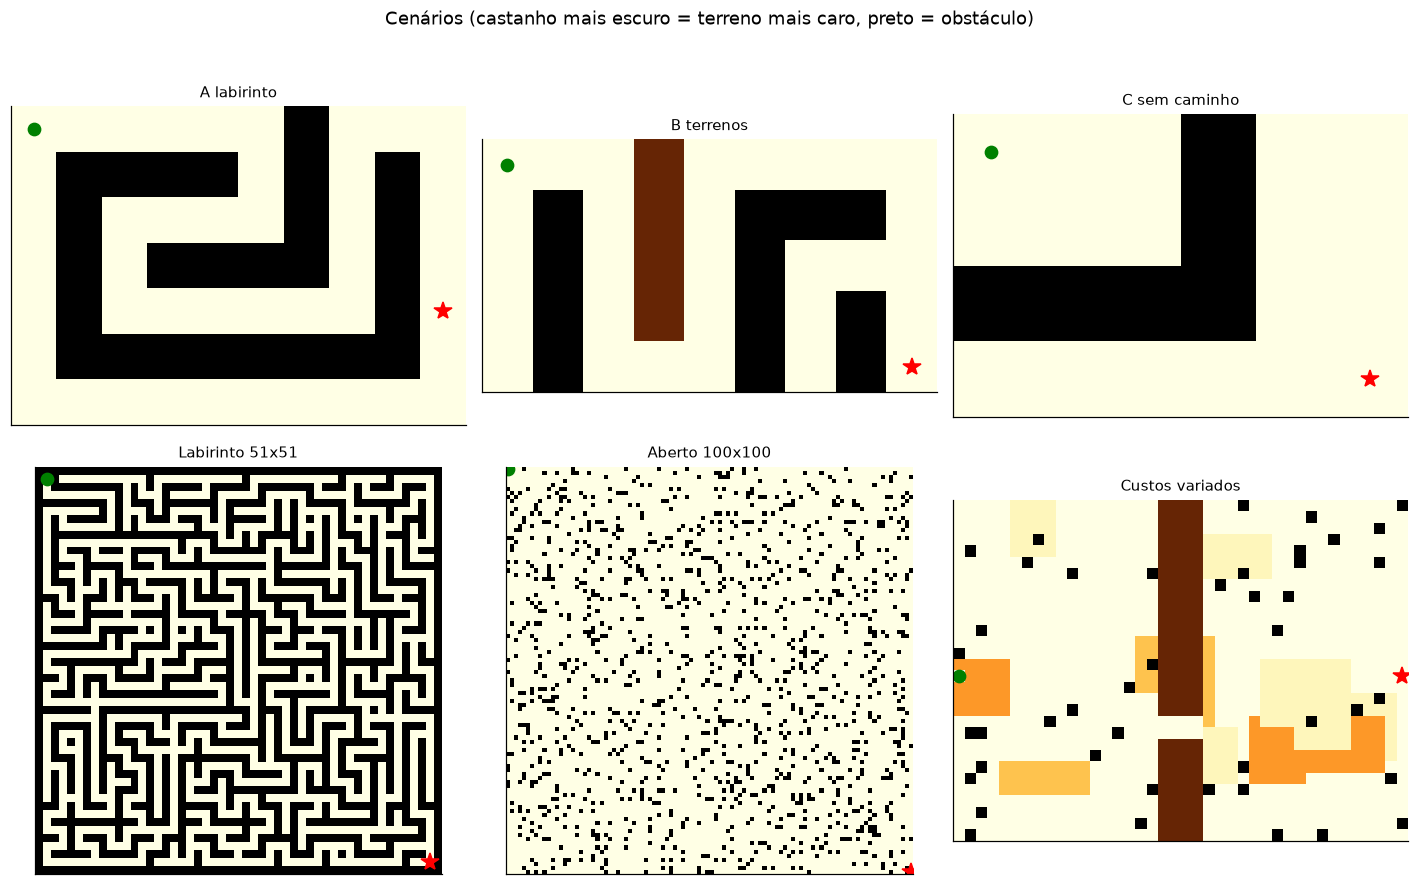

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, (nome, g) in zip(axs.ravel(), cenarios.items()):
    mostrar(g, None, None, g.start, g.goal, nome, ax)
fig.suptitle("Cenários (castanho mais escuro = terreno mais caro, preto = obstáculo)", y=1.0)
fig.tight_layout()
plt.show()

## 2. Validação com o Anexo A

Antes de qualquer experiência, confirmamos que o Dijkstra dá os custos ótimos do enunciado.

In [4]:
esperado = {                                   # (4 direções, 8 direções)
    "A labirinto":   (17, 17),
    "B terrenos":    (20, 18.83),
    "C sem caminho": (math.inf, math.inf),
}
linhas = []
for nome, (e4, e8) in esperado.items():
    g = cenarios[nome]
    c4 = dij(g, 4).cost
    c8 = dij(g, 8).cost
    ok = math.isclose(c4, e4, abs_tol=0.01) and math.isclose(c8, e8, abs_tol=0.01)
    linhas.append({"Cenário": nome,
                   "4 dir. obtido": c4, "4 dir. esperado": e4,
                   "8 dir. obtido": round(c8, 2), "8 dir. esperado": e8,
                   "OK": "✓" if ok else "✗"})
pd.DataFrame(linhas).set_index("Cenário")

,4 dir. obtido,4 dir. esperado,8 dir. obtido,8 dir. esperado,OK
Cenário,,,,,
A labirinto,17.0,17.0,17.00,17.00,✓
B terrenos,20.0,20.0,18.83,18.83,✓
C sem caminho,inf,inf,inf,inf,✓


## 3. Dijkstra vs A*

Corremos Dijkstra e A* (com quatro heurísticas) em todos os cenários, em 4 e 8 direções.
Cada tempo é a **média de 5 execuções**. A optimalidade compara-se com o custo do Dijkstra.

In [5]:
# (algoritmo, heurística, peso w, função). O Dijkstra tem de ser o primeiro.
configs = [
    ("Dijkstra", "-",          1, dij),
    ("A*", "Manhattan",        1, ast(manhattan)),
    ("A*", "Euclidiana",       1, ast(euclidean)),
    ("A*", "Chebyshev",        1, ast(chebyshev)),
    ("A*", "Octile",           1, ast(octile)),
]
df = correr(cenarios, configs, repeticoes=5)
df.to_csv("../results/tables/principal.csv", index=False)
print(f"{len(df)} experiências concluídas")
df.round(3)

60 experiências concluídas


,cenario,direcoes,algoritmo,heuristica,w,custo,expandidos,gerados,fronteira_max,tempo_ms,passos,otimo,gap_pct
0,A labirinto,4,Dijkstra,-,1,17.000,34,35,2,0.144,17.0,True,0.000
1,A labirinto,4,A*,Manhattan,1,17.000,27,28,2,0.072,17.0,True,0.000
2,A labirinto,4,A*,Euclidiana,1,17.000,27,28,2,0.097,17.0,True,0.000
3,A labirinto,4,A*,Chebyshev,1,17.000,27,28,2,0.081,17.0,True,0.000
4,A labirinto,4,A*,Octile,1,17.000,27,28,2,0.107,17.0,True,0.000
5,A labirinto,8,Dijkstra,-,1,17.000,34,35,2,0.138,17.0,True,0.000
6,A labirinto,8,A*,Manhattan,1,17.000,27,28,2,0.106,17.0,True,0.000
7,A labirinto,8,A*,Euclidiana,1,17.000,27,28,2,0.103,17.0,True,0.000
8,A labirinto,8,A*,Chebyshev,1,17.000,27,28,2,0.083,17.0,True,0.000
9,A labirinto,8,A*,Octile,1,17.000,27,28,2,0.087,17.0,True,0.000


### 3.1 Nós expandidos e memória (4 direções)

In [6]:
t4 = (df[df.direcoes == 4]
      .pivot_table(index="cenario", columns=["algoritmo", "heuristica"], values="expandidos"))
print("Nós expandidos (4 direções)")
t4.rename_axis("Cenário").astype(int)

Nós expandidos (4 direções)


algoritmo              A*                             Dijkstra
heuristica      Chebyshev Euclidiana Manhattan Octile        -
Cenário                                                       
A labirinto            27         27        27     27       34
Aberto 100x100       8459       8458       566   8381     8799
B terrenos             29         29        28     29       30
C sem caminho           6          6         6      6        6
Custos variados       638        584       371    496     1013
Labirinto 51x51       993        969       855    960     1171

In [7]:
d = df[df.direcoes == 4]
dij_exp = d[d.algoritmo == "Dijkstra"].set_index("cenario")["expandidos"]
ganho = {}
for h in ["Manhattan", "Euclidiana", "Chebyshev", "Octile"]:
    a = d[d.heuristica == h].set_index("cenario")["expandidos"]
    ganho[h] = 100 * (1 - a / dij_exp)                  # % de nós poupados
print("Nós poupados pelo A* face ao Dijkstra, em % (4 direções)")
pd.DataFrame(ganho).rename_axis("Cenário").round(1)


Nós poupados pelo A* face ao Dijkstra, em % (4 direções)


,Manhattan,Euclidiana,Chebyshev,Octile
Cenário,,,,
A labirinto,20.6,20.6,20.6,20.6
B terrenos,6.7,3.3,3.3,3.3
C sem caminho,0.0,0.0,0.0,0.0
Labirinto 51x51,27.0,17.3,15.2,18.0
Aberto 100x100,93.6,3.9,3.9,4.8
Custos variados,63.4,42.3,37.0,51.0


In [8]:
m = df[df.direcoes == 4].pivot_table(index="cenario", columns=["algoritmo", "heuristica"],
                                     values="fronteira_max")
print("Pico da fronteira (4 direções): indicador de memória")
m.rename_axis("Cenário").astype(int)

Pico da fronteira (4 direções): indicador de memória


algoritmo              A*                             Dijkstra
heuristica      Chebyshev Euclidiana Manhattan Octile        -
Cenário                                                       
A labirinto             2          2         2      2        2
Aberto 100x100        203        176       464    238      102
B terrenos              6          6         5      6        5
C sem caminho           3          3         2      3        2
Custos variados       128        129       104    119       69
Labirinto 51x51        20         18        20     20       19

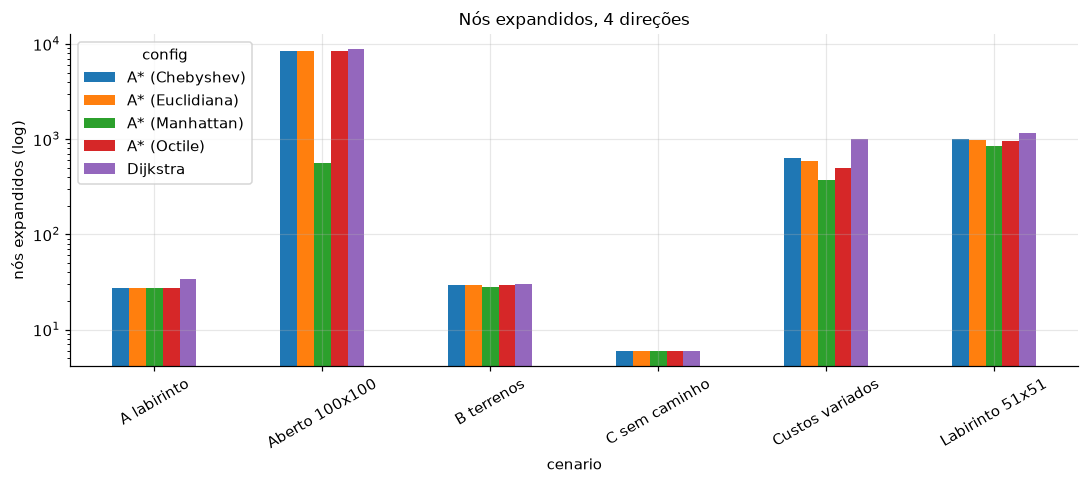

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
grafico_expandidos(df, 4, ax)
fig.tight_layout()
fig.savefig("../results/figures/expandidos_4dir.png", dpi=150)
plt.show()

### 3.2 Caminho encontrado e nós explorados

A zona azul mostra os nós explorados. O A* explora menos porque a heurística o guia
para o objetivo.

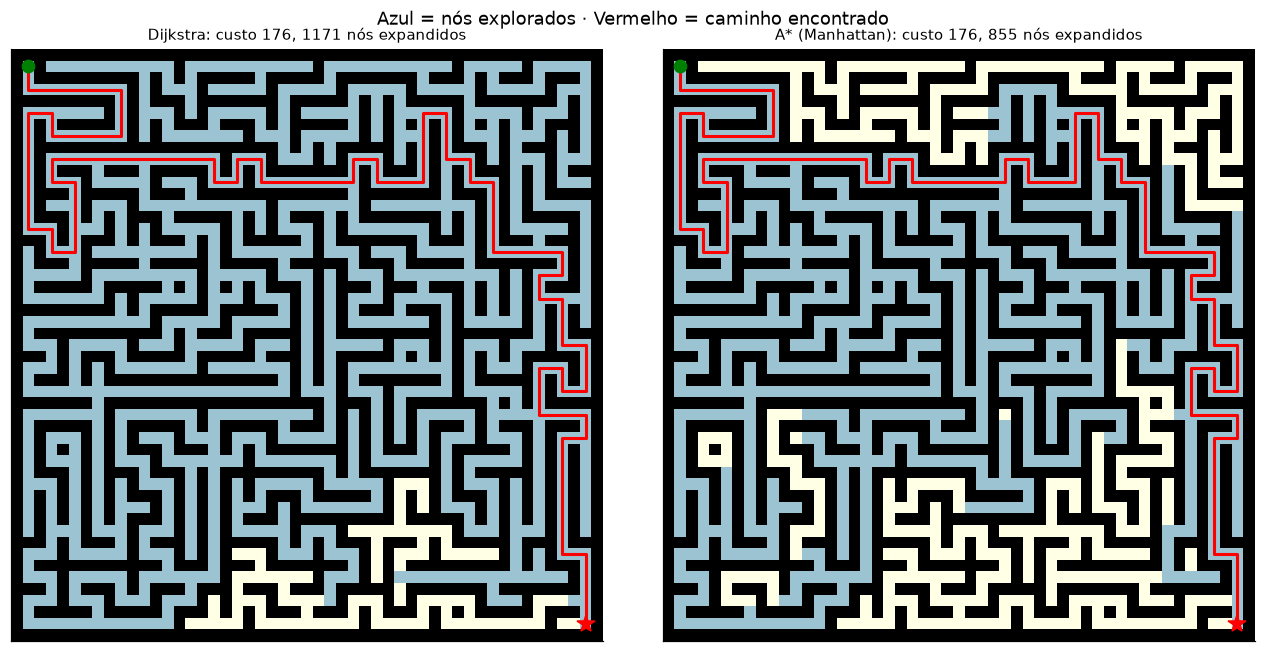

In [10]:
g = cenarios["Labirinto 51x51"]
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, (nome, res) in zip(axs, [("Dijkstra", dij(g, 4)),
                                 ("A* (Manhattan)", ast(manhattan)(g, 4))]):
    mostrar(g, res.path, res.explored, g.start, g.goal,
            f"{nome}: custo {res.cost:.0f}, {res.expanded} nós expandidos", ax)
fig.suptitle("Azul = nós explorados · Vermelho = caminho encontrado")
fig.tight_layout()
fig.savefig("../results/figures/labirinto_caminhos.png", dpi=150)
plt.show()

### 3.3 Custos variados: o caminho mais curto não é o mais barato

Comparamos o caminho com **menos passos** (ignorando custos) com o de **menor custo**.

Menos passos: 39 passos, custo real 104
Menor custo:  55 passos, custo real 66


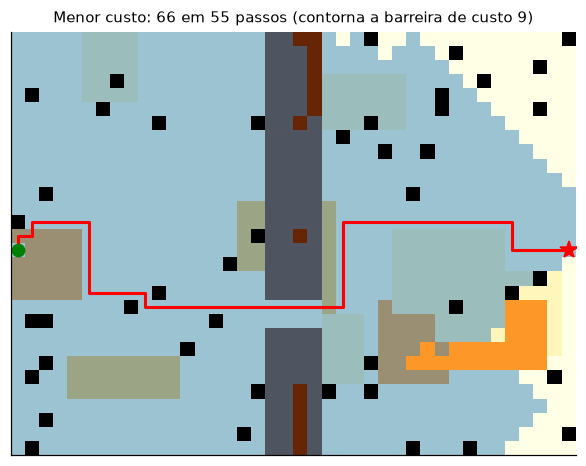

In [11]:
g = cenarios["Custos variados"]

# grelha com todos os custos a 1: o Dijkstra dá o caminho com menos passos
unit = Grid([[None if v is None else 1 for v in linha] for linha in g.cost], g.start, g.goal)
r_passos = dij(unit, 4)
r_otimo = dij(g, 4)
print(f"Menos passos: {len(r_passos.path) - 1} passos, custo real {g.path_cost(r_passos.path, 4):.0f}")
print(f"Menor custo:  {len(r_otimo.path) - 1} passos, custo real {r_otimo.cost:.0f}")

fig, ax = plt.subplots(figsize=(10, 5))
mostrar(g, r_otimo.path, r_otimo.explored, g.start, g.goal,
        f"Menor custo: {r_otimo.cost:.0f} em {len(r_otimo.path) - 1} passos (contorna a barreira de custo 9)", ax)
fig.savefig("../results/figures/custos_variados.png", dpi=150)
plt.show()

## 4. Heurísticas e modelo de movimento

| Heurística | 4 direções | 8 direções |
|---|---|---|
| Manhattan | admissível e consistente | **não admissível** |
| Euclidiana | admissível e consistente (mais fraca) | admissível e consistente |
| Chebyshev | admissível e consistente (mais fraca) | admissível e consistente |
| Octile *(extra)* | admissível (fraca) | admissível e consistente, a mais informada |

**Porquê?** Em 8 direções, uma diagonal avança 2 unidades de Manhattan por um custo de √2,
por isso o Manhattan sobrestima o custo real e o A* pode devolver caminhos não ótimos.

In [12]:
d8 = df[(df.direcoes == 8) & (df.algoritmo == "A*")]
print("Desvio ao custo ótimo, A* em 8 direções, em % (0 = ótimo)")
d8.pivot_table(index="cenario", columns="heuristica", values="gap_pct").rename_axis("Cenário").round(2)

Desvio ao custo ótimo, A* em 8 direções, em % (0 = ótimo)


heuristica,Chebyshev,Euclidiana,Manhattan,Octile
Cenário,,,,
A labirinto,0.0,0.0,0.00,0.0
Aberto 100x100,0.0,0.0,3.05,0.0
B terrenos,0.0,0.0,0.00,0.0
Custos variados,0.0,0.0,0.00,0.0
Labirinto 51x51,0.0,0.0,0.00,0.0


,Custo,Ótimo?
Algoritmo,,
Dijkstra,8.243,✓
A* Manhattan,8.828,✗
A* Euclidiana,8.243,✓
A* Chebyshev,8.243,✓
A* Octile,8.243,✓


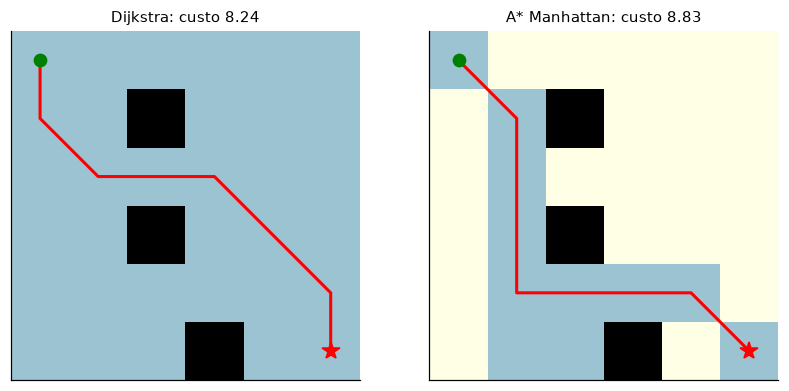

In [13]:
# contra-exemplo pequeno onde o Manhattan falha em 8 direções
exemplo = Grid.from_text("S.....\n..#...\n......\n..#...\n......\n...#.G")
heuristicas = {"Manhattan": manhattan, "Euclidiana": euclidean,
               "Chebyshev": chebyshev, "Octile": octile}

otimo = dij(exemplo, 8).cost
linhas = [{"Algoritmo": "Dijkstra", "Custo": round(otimo, 3), "Ótimo?": "✓"}]
for nome, h in heuristicas.items():
    c = ast(h)(exemplo, 8).cost
    linhas.append({"Algoritmo": f"A* {nome}", "Custo": round(c, 3),
                   "Ótimo?": "✓" if abs(c - otimo) < 1e-9 else "✗"})
display(pd.DataFrame(linhas).set_index("Algoritmo"))

fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (nome, res) in zip(axs, [("Dijkstra", dij(exemplo, 8)),
                                 ("A* Manhattan", ast(manhattan)(exemplo, 8))]):
    mostrar(exemplo, res.path, res.explored, exemplo.start, exemplo.goal,
            f"{nome}: custo {res.cost:.2f}", ax)
plt.show()

## 5. Heurística não admissível: Weighted A*

Multiplicamos a heurística por um peso **w > 1**. Com w = 1 o A* é ótimo; com w maior
expande menos nós, mas pode devolver caminhos mais caros. Medimos o compromisso.

In [14]:
pesos = [1, 1.2, 1.5, 2, 3, 5]
configs_w = [("Dijkstra", "-", 1, dij)] + [
    ("A*", "Manhattan", w, ast(manhattan, w)) for w in pesos
]
grandes = {k: cenarios[k] for k in ("Labirinto 51x51", "Aberto 100x100", "Custos variados")}
df_w = correr(grandes, configs_w, direcoes_lista=(4,), repeticoes=3)
df_w.to_csv("../results/tables/pesos.csv", index=False)

(df_w[df_w.algoritmo == "A*"][["cenario", "w", "custo", "gap_pct", "expandidos", "tempo_ms"]]
   .rename(columns={"cenario": "Cenário", "gap_pct": "Desvio (%)",
                    "expandidos": "Nós", "tempo_ms": "Tempo (ms)"})
   .round(2).set_index(["Cenário", "w"]))

custo  Desvio (%)  Nós  Tempo (ms)
Cenário         w                                      
Labirinto 51x51 1.0  176.0        0.00  855        2.14
                1.2  176.0        0.00  806        2.11
                1.5  176.0        0.00  583        1.31
                2.0  196.0       11.36  788        1.77
                3.0  224.0       27.27  412        1.77
                5.0  224.0       27.27  375        1.14
Aberto 100x100  1.0  198.0        0.00  566        2.10
                1.2  206.0        4.04  280        0.89
                1.5  212.0        7.07  267        0.93
                2.0  216.0        9.09  261        0.83
                3.0  224.0       13.13  241        0.79
                5.0  224.0       13.13  238        0.78
Custos variados 1.0   66.0        0.00  371        1.27
                1.2   66.0        0.00  286        0.93
                1.5   70.0        6.06  166        0.55
                2.0   74.0       12.12   81        0.27
                3.0   74.0       12.12   67        0.23
                5.0  104.0       57.58   51        0.25

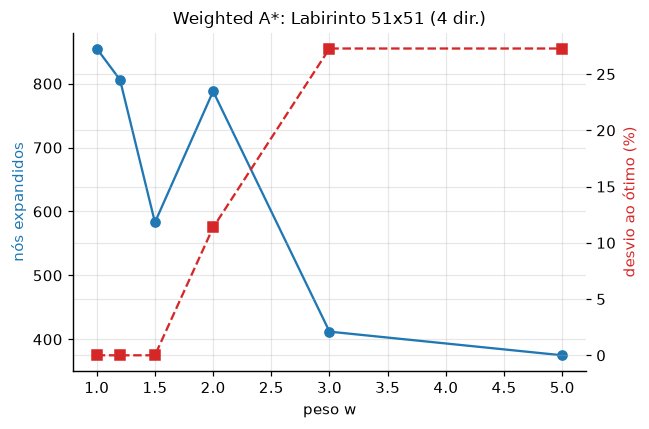

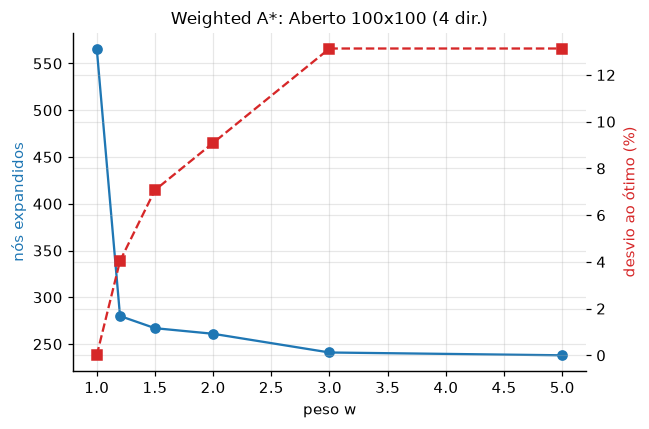

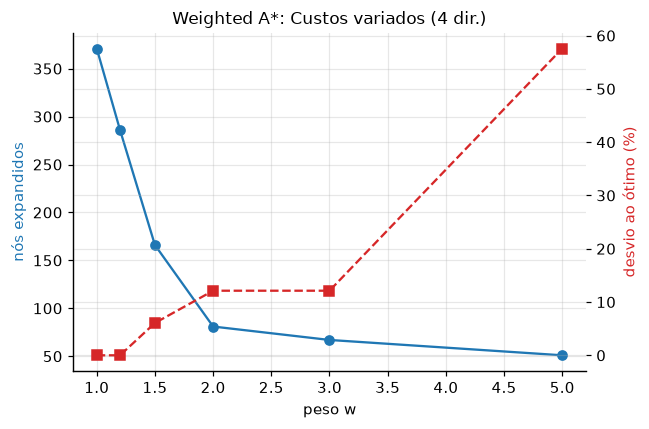

In [15]:
for nome in grandes:
    fig = grafico_peso(df_w, nome, "Manhattan", 4)
    fig.savefig(f"../results/figures/peso_{nome.split()[0].lower()}.png", dpi=150)
    plt.show()

## 6. Extensão: Weighted A*

A secção 5 é a extensão escolhida: estudo sistemático do compromisso entre qualidade
do caminho e rapidez ao variar o peso da heurística.

In [16]:
d = df[df.direcoes == 4]
dij_exp = d[d.algoritmo == "Dijkstra"].set_index("cenario")["expandidos"]
ganho = {h: 100 * (1 - d[d.heuristica == h].set_index("cenario")["expandidos"] / dij_exp)
         for h in ["Manhattan", "Euclidiana", "Chebyshev", "Octile"]}

print("=== NÓS POUPADOS (%) 4 DIREÇÕES ===")
print(pd.DataFrame(ganho).round(1).to_string())

print("\n=== DESVIO AO ÓTIMO (%) A* 8 DIREÇÕES ===")
d8 = df[(df.direcoes == 8) & (df.algoritmo == "A*")]
print(d8.pivot_table(index="cenario", columns="heuristica", values="gap_pct").round(2).to_string())

print("\n=== CONTRA-EXEMPLO 8 DIREÇÕES ===")
print(pd.DataFrame(linhas).to_string(index=False))

print("\n=== CUSTOS VARIADOS ===")
print(f"Menos passos: {len(r_passos.path) - 1} passos, custo {g.path_cost(r_passos.path, 4):.0f}")
print(f"Menor custo:  {len(r_otimo.path) - 1} passos, custo {r_otimo.cost:.0f}")

=== NÓS POUPADOS (%) 4 DIREÇÕES ===
                 Manhattan  Euclidiana  Chebyshev  Octile
cenario                                                  
A labirinto           20.6        20.6       20.6    20.6
B terrenos             6.7         3.3        3.3     3.3
C sem caminho          0.0         0.0        0.0     0.0
Labirinto 51x51       27.0        17.3       15.2    18.0
Aberto 100x100        93.6         3.9        3.9     4.8
Custos variados       63.4        42.3       37.0    51.0

=== DESVIO AO ÓTIMO (%) A* 8 DIREÇÕES ===
heuristica       Chebyshev  Euclidiana  Manhattan  Octile
cenario                                                  
A labirinto            0.0         0.0       0.00     0.0
Aberto 100x100         0.0         0.0       3.05     0.0
B terrenos             0.0         0.0       0.00     0.0
Custos variados        0.0         0.0       0.00     0.0
Labirinto 51x51        0.0         0.0       0.00     0.0

=== CONTRA-EXEMPLO 8 DIREÇÕES ===
    Algoritmo  C

## 7. Conclusões

### Resumo

| Pergunta | Resposta curta |
|---|---|
| O A\* compensa? | **Sim, quando a heurística combina com o mapa** (até −93,6% de nós) |
| Quando compensa pouco? | Labirintos, mapas pequenos e cenários sem caminho |
| Qual a melhor heurística? | **Manhattan** em 4 direções, **Octile** em 8 direções |
| O Manhattan serve em 8 direções? | **Não**: deixa de ser ótimo (+3,05% no espaço aberto) |
| O Weighted A\* compensa? | Ganha velocidade, mas o custo sobe a partir de um w que depende do mapa |

---

### 1. Quando compensa o A\*

O ganho depende de a heurística refletir o custo real do mapa.

- **Espaço aberto 100×100 (4 direções):** o A\* com Manhattan expande **566 nós** contra 8799 do Dijkstra (**−93,6%**) e é cerca de **12× mais rápido** (2,2 ms contra 27,5 ms).
- **Custos variados:** poupa **63,4%** dos nós.
- **Heurísticas mais fracas** (Euclidiana, Chebyshev, Octile) poupam apenas 4–5% no espaço aberto, porque subestimam muito o custo real.

### 2. Quando compensa pouco

- **Labirinto 51×51:** poupa só **15–27%**. As heurísticas ignoram as paredes e o A\* entra em becos sem saída.
- **Cenário sem caminho (C):** o A\* explora a mesma região que o Dijkstra (6 nós).
- **Mapas pequenos (A e B):** a diferença é mínima e os tempos (< 1 ms) são ruído de medição.

### 3. Menos nós não é sempre menos tempo

No espaço aberto, a Chebyshev (30,1 ms) e a Octile (32,6 ms) demoram **mais** do que o Dijkstra (27,5 ms). O custo de calcular a heurística anula a poupança de nós.

### 4. Heurística e modelo de movimento

- **4 direções:** as quatro heurísticas devolvem sempre o caminho ótimo.
- **8 direções:** o Manhattan **não é admissível**. No espaço aberto devolve custo **158,17** contra **153,48** (+3,05%).
- Nos outros cenários não falha: terrenos de custo ≥ 2 e corredores estreitos escondem a sobrestimação.
- A **Octile** é a mais informada entre as admissíveis em 8 direções: poupa **69%** dos nós no espaço aberto.

### 5. Weighted A\*

O peso troca qualidade por velocidade, e o ponto de rutura depende do mapa:

| Cenário | Deixa de ser ótimo | Exemplo |
|---|---|---|
| Espaço aberto | entre w = 1 e 1,2 | w = 1,2: +4,0% de custo, −51% de nós |
| Custos variados | entre w = 1,2 e 1,5 | w = 2: +12,1% de custo, **−78% de nós** |
| Labirinto | entre w = 1,5 e 2 | w = 2: +11,4% de custo |

O custo respeita sempre o limite teórico `custo ≤ w × ótimo`.

### 6. Memória e limitações

- O A\* reduz os nós expandidos, mas o **pico da fronteira pode subir**: no espaço aberto, 464 com o Manhattan contra 102 com o Dijkstra.
- Em grelhas grandes, o Dijkstra expande quase todas as células (8799 em 10 000).
- O desempenho do A\* é **sensível à escolha da heurística**: a mesma pesquisa varia de 566 a 8458 nós conforme a heurística.

### 7. O que não esperávamos

1. O A\* pode ser **mais lento** do que o Dijkstra, apesar de expandir menos nós.
2. O peso **não reduz sempre os nós**: no labirinto, w = 2 expande mais (788) do que w = 1,5 (583).
3. No cenário B em 4 direções há um **empate**: um caminho de 12 passos e outro de 20, ambos com custo 20.

---
*Declaração de uso de IA generativa: ver o mini-relatório.*